In [1]:
import pandas as pd

In [2]:
customers = pd.read_csv(r"C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\data\raw\customers.csv")

In [3]:
customers.shape

(20000, 5)

In [4]:
customers.head()

,customer_id,created_at,country_code,acquisition_channel,customer_segment
0,C000001,2023-01-01,DE,organic,consumer
1,C000002,2023-01-01,US,paid_search,small_business
2,C000003,2023-01-01,US,paid_social,consumer
3,C000004,2023-01-01,US,affiliate,small_business
4,C000005,2023-01-01,GB,organic,consumer


In [5]:
customers.columns

Index(['customer_id', 'created_at', 'country_code', 'acquisition_channel',
       'customer_segment'],
      dtype='str')

In [6]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   customer_id          20000 non-null  str  
 1   created_at           20000 non-null  str  
 2   country_code         20000 non-null  str  
 3   acquisition_channel  20000 non-null  str  
 4   customer_segment     20000 non-null  str  
dtypes: str(5)
memory usage: 781.4 KB


In [7]:
customers.isnull().sum()

customer_id            0
created_at             0
country_code           0
acquisition_channel    0
customer_segment       0
dtype: int64

In [8]:
customers.duplicated().sum()

np.int64(0)

In [9]:
customers["customer_id"].duplicated().sum()

np.int64(0)

In [10]:
customers.isnull().sum()

customer_id            0
created_at             0
country_code           0
acquisition_channel    0
customer_segment       0
dtype: int64

In [11]:
customers.duplicated().sum()

np.int64(0)

In [12]:
customers["customer_id"].duplicated().sum()

np.int64(0)

In [13]:
customers["created_at"] = pd.to_datetime(customers["created_at"])

In [14]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          20000 non-null  str           
 1   created_at           20000 non-null  datetime64[us]
 2   country_code         20000 non-null  str           
 3   acquisition_channel  20000 non-null  str           
 4   customer_segment     20000 non-null  str           
dtypes: datetime64[us](1), str(4)
memory usage: 781.4 KB


In [15]:
customers["created_at"].dt.year.value_counts().sort_index()

created_at
2023    20000
Name: count, dtype: int64

In [16]:
customers["country_code"].value_counts().head(10)

country_code
US    12745
GB     2020
CA     1968
AU     1654
DE     1613
Name: count, dtype: int64

In [17]:
customers["acquisition_channel"].value_counts()

acquisition_channel
organic        6117
paid_search    4994
paid_social    3932
referral       2920
affiliate      2037
Name: count, dtype: int64

In [18]:
orders = pd.read_csv(r"C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\data\raw\orders.csv")

In [19]:
orders.shape

(100000, 9)

In [20]:
orders.head()

,order_id,customer_id,ordered_at,order_status,currency,subtotal,tax_amount,shipping_amount,order_total
0,O0000001,C002898,2025-05-09T16:24:59Z,completed,USD,19.05,1.52,9.99,30.56
1,O0000002,C009320,2025-12-12T08:14:21Z,cancelled,USD,646.42,51.71,0.00,698.13
2,O0000003,C015738,2024-11-20T20:22:01Z,completed,USD,472.48,37.80,0.00,510.28
3,O0000004,C011513,2024-09-17T14:05:46Z,completed,USD,329.55,26.36,0.00,355.91
4,O0000005,C011006,2025-09-28T01:29:00Z,completed,USD,600.16,48.01,0.00,648.17


In [21]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         100000 non-null  str    
 1   customer_id      100000 non-null  str    
 2   ordered_at       100000 non-null  str    
 3   order_status     100000 non-null  str    
 4   currency         100000 non-null  str    
 5   subtotal         100000 non-null  float64
 6   tax_amount       100000 non-null  float64
 7   shipping_amount  100000 non-null  float64
 8   order_total      100000 non-null  float64
dtypes: float64(4), str(5)
memory usage: 6.9 MB


In [22]:
orders["order_id"].duplicated().sum()

np.int64(0)

In [23]:
orders["order_status"].value_counts()

order_status
completed             89114
partially_refunded     5217
cancelled              2976
refunded               2693
Name: count, dtype: int64

In [24]:
orders["order_status"].value_counts(normalize=True) * 100

order_status
completed             89.114
partially_refunded     5.217
cancelled              2.976
refunded               2.693
Name: proportion, dtype: float64

In [25]:
orders["ordered_at"] = pd.to_datetime(orders["ordered_at"], utc=True)

In [26]:
orders["ordered_at"].dtype

datetime64[us, UTC]

In [27]:
orders["ordered_at"].min(), orders["ordered_at"].max()

(Timestamp('2023-01-01 00:27:20+0000', tz='UTC'),
 Timestamp('2025-12-31 23:59:03+0000', tz='UTC'))

In [28]:
orders["customer_id"].isin(customers["customer_id"]).all()

np.True_

In [29]:
orders["order_total"].describe()

count    100000.000000
mean        653.645842
std         484.630196
min          11.640000
25%         288.640000
50%         540.360000
75%         904.340000
max        4742.760000
Name: order_total, dtype: float64

In [30]:
completed_orders = orders[orders["order_status"] == "completed"]


In [31]:
completed_orders["order_total"].mean()

np.float64(655.2688753731176)

In [32]:
completed_orders["order_total"].sum()

np.float64(58393630.56)

In [33]:
orders["ordered_at"].dt.year.value_counts().sort_index()

ordered_at
2023    33309
2024    33229
2025    33462
Name: count, dtype: int64

In [34]:
completed_orders.groupby(
    completed_orders["ordered_at"].dt.year
)["order_total"].sum()

ordered_at
2023    19374707.57
2024    19446519.65
2025    19572403.34
Name: order_total, dtype: float64

In [35]:
monthly_revenue = completed_orders.groupby(
    completed_orders["ordered_at"].dt.to_period("M")
)["order_total"].sum()

monthly_revenue


C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_8532\986181807.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  completed_orders["ordered_at"].dt.to_period("M")


ordered_at
2023-01    1589196.08
2023-02    1495020.76
2023-03    1766306.46
2023-04    1644914.53
2023-05    1605046.48
2023-06    1538655.56
2023-07    1649473.18
2023-08    1554272.91
2023-09    1587639.32
2023-10    1680167.55
2023-11    1653621.37
2023-12    1610393.37
2024-01    1625078.39
2024-02    1608817.91
2024-03    1673625.72
2024-04    1526332.59
2024-05    1630898.04
2024-06    1612008.80
2024-07    1646003.61
2024-08    1725626.09
2024-09    1582130.58
2024-10    1618776.01
2024-11    1595482.75
2024-12    1601739.16
2025-01    1620061.61
2025-02    1542429.68
2025-03    1689141.15
2025-04    1606273.21
2025-05    1681856.85
2025-06    1607396.96
2025-07    1669019.64
2025-08    1682361.32
2025-09    1587053.08
2025-10    1637222.87
2025-11    1600617.36
2025-12    1648969.61
Freq: M, Name: order_total, dtype: float64

In [36]:
monthly_revenue.idxmax(), monthly_revenue.max()

(Period('2023-03', 'M'), np.float64(1766306.46))

In [37]:
monthly_revenue.idxmin(), monthly_revenue.min()

(Period('2023-02', 'M'), np.float64(1495020.76))

In [38]:
monthly_revenue.idxmax(), monthly_revenue.max()

(Period('2023-03', 'M'), np.float64(1766306.46))

In [39]:
monthly_revenue.idxmin(), monthly_revenue.min()

(Period('2023-02', 'M'), np.float64(1495020.76))

In [40]:
order_items = pd.read_csv(r"C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\data\raw\order_items.csv")

In [41]:
order_items.shape

(237537, 7)

In [42]:
order_items.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount_amount,line_total
0,OI00000001,O0000001,P00871,1,19.05,0.00,19.05
1,OI00000002,O0000002,P01099,1,295.03,14.75,280.28
2,OI00000003,O0000002,P00505,1,280.46,0.00,280.46
3,OI00000004,O0000002,P00398,1,85.68,0.00,85.68
4,OI00000005,O0000003,P00717,2,117.78,35.33,200.23


In [43]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 237537 entries, 0 to 237536
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_item_id    237537 non-null  str    
 1   order_id         237537 non-null  str    
 2   product_id       237537 non-null  str    
 3   quantity         237537 non-null  int64  
 4   unit_price       237537 non-null  float64
 5   discount_amount  237537 non-null  float64
 6   line_total       237537 non-null  float64
dtypes: float64(3), int64(1), str(3)
memory usage: 12.7 MB


In [44]:
order_items["order_item_id"].duplicated().sum()

np.int64(0)

In [45]:
order_items["order_id"].isin(orders["order_id"]).all()

np.True_

In [46]:
order_items["quantity"].sum()

np.int64(328166)

In [47]:
order_items["quantity"].mean()

np.float64(1.3815363501265066)

In [48]:
order_items.isnull().sum()

order_item_id      0
order_id           0
product_id         0
quantity           0
unit_price         0
discount_amount    0
line_total         0
dtype: int64

In [49]:
order_items.duplicated().sum()

np.int64(0)

In [50]:
products = pd.read_csv(r"C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\data\raw\products.csv")

In [51]:
products.shape

(1200, 6)

In [52]:
products.head()

,product_id,sku,product_name,category,unit_cost,list_price
0,P00001,APP-00001,Apparel Item 0001,apparel,49.88,71.24
1,P00002,ELE-00002,Electronics Item 0002,electronics,106.75,165.20
2,P00003,HOM-00003,Home Item 0003,home,39.22,100.56
3,P00004,OUT-00004,Outdoors Item 0004,outdoors,32.60,67.66
4,P00005,BEA-00005,Beauty Item 0005,beauty,41.38,75.32


In [53]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    1200 non-null   str    
 1   sku           1200 non-null   str    
 2   product_name  1200 non-null   str    
 3   category      1200 non-null   str    
 4   unit_cost     1200 non-null   float64
 5   list_price    1200 non-null   float64
dtypes: float64(2), str(4)
memory usage: 56.4 KB


In [54]:
products["product_id"].duplicated().sum()

np.int64(0)

In [55]:
products.isnull().sum()

product_id      0
sku             0
product_name    0
category        0
unit_cost       0
list_price      0
dtype: int64

In [56]:
products.duplicated().sum()

np.int64(0)

In [57]:
order_items["product_id"].isin(products["product_id"]).all()

np.True_

In [58]:
products["category"].value_counts()

category
apparel        200
electronics    200
home           200
outdoors       200
beauty         200
office         200
Name: count, dtype: int64

In [59]:
products.groupby("category")["list_price"].mean().round(2)

category
apparel        196.57
beauty         195.23
electronics    190.75
home           179.65
office         189.47
outdoors       191.78
Name: list_price, dtype: float64

In [60]:
products.groupby("category")["unit_cost"].mean().round(2)

category
apparel        94.98
beauty         94.98
electronics    90.26
home           86.48
office         89.45
outdoors       92.75
Name: unit_cost, dtype: float64

In [61]:
products["gross_profit_per_unit"] = products["list_price"] - products["unit_cost"]

In [62]:
products["gross_margin_pct"] = (
    products["gross_profit_per_unit"] / products["list_price"]
) * 100

In [63]:
products.groupby("category")[
    ["gross_profit_per_unit", "gross_margin_pct"]
].mean().round(2)

,gross_profit_per_unit,gross_margin_pct
category,,
apparel,101.59,49.84
beauty,100.25,49.16
electronics,100.49,50.68
home,93.17,49.21
office,100.03,50.50
outdoors,99.03,49.60


In [64]:
payments = pd.read_csv(r"C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\data\raw\payments.csv")

In [65]:
payments.shape

(105388, 6)

In [66]:
payments.head()

,payment_id,order_id,paid_at,payment_method,payment_status,amount
0,PAY0000001,O0000001,2025-05-11T12:19:59Z,card,succeeded,30.56
1,PAY0000002,O0000002,2025-12-12T08:14:21Z,card,failed,698.13
2,PAY0000003,O0000003,2024-11-20T20:22:01Z,card,succeeded,510.28
3,PAY0000004,O0000004,2024-09-18T13:24:26Z,card,succeeded,355.91
4,PAY0000005,O0000005,2025-09-29T00:26:52Z,card,succeeded,648.17


In [67]:
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 105388 entries, 0 to 105387
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   payment_id      105388 non-null  str    
 1   order_id        105388 non-null  str    
 2   paid_at         105388 non-null  str    
 3   payment_method  105388 non-null  str    
 4   payment_status  105388 non-null  str    
 5   amount          105388 non-null  float64
dtypes: float64(1), str(5)
memory usage: 4.8 MB


In [68]:
payments["payment_id"].duplicated().sum()

np.int64(0)

In [69]:
payments.isnull().sum()

payment_id        0
order_id          0
paid_at           0
payment_method    0
payment_status    0
amount            0
dtype: int64

In [70]:
payments.duplicated().sum()

np.int64(0)

In [71]:
payments["order_id"].isin(orders["order_id"]).all()

np.True_

In [72]:
payments["payment_status"].value_counts()

payment_status
succeeded    97024
failed        8364
Name: count, dtype: int64

In [73]:
payments["payment_status"].value_counts(normalize=True).mul(100).round(2)

payment_status
succeeded    92.06
failed        7.94
Name: proportion, dtype: float64

In [74]:
payments["payment_method"].value_counts()

payment_method
card             75865
paypal           21058
bank_transfer     8465
Name: count, dtype: int64

In [75]:
payments.groupby("payment_status")["amount"].agg(
    ["count", "sum", "mean"]
).round(2)

,count,sum,mean
payment_status,,,
failed,8364,5468038.19,653.76
succeeded,97024,63458562.67,654.05


In [76]:
payments.groupby(["payment_method", "payment_status"]).size().unstack(fill_value=0)

payment_status,failed,succeeded
payment_method,,
bank_transfer,728,7737
card,6012,69853
paypal,1624,19434


In [77]:
payment_success = payments.pivot_table(
    index="payment_method",
    columns="payment_status",
    values="payment_id",
    aggfunc="count",
    fill_value=0
)

payment_success["success_rate"] = (
    payment_success["succeeded"] /
    (payment_success["succeeded"] + payment_success["failed"])
) * 100

payment_success.round(2)

payment_status,failed,succeeded,success_rate
payment_method,,,
bank_transfer,728,7737,91.40
card,6012,69853,92.08
paypal,1624,19434,92.29


In [78]:
refunds= pd.read_csv(r"C:\Users\AYUSH KUMAR\OneDrive\Desktop\ecommerce_customer_analytics\data\raw\refunds.csv")

In [79]:
refunds.shape

(7910, 6)

In [80]:
refunds.head()

,refund_id,payment_id,order_id,refunded_at,refund_reason,amount
0,R000001,PAY0000016,O0000013,2025-07-20T18:11:46Z,damaged,34.50
1,R000002,PAY0000021,O0000018,2024-11-28T09:21:28Z,customer_return,1672.37
2,R000003,PAY0000032,O0000029,2023-04-01T15:50:20Z,duplicate,74.50
3,R000004,PAY0000040,O0000037,2023-08-11T19:50:45Z,customer_return,112.90
4,R000005,PAY0000041,O0000038,2024-10-21T06:30:39Z,late_delivery,560.70


In [81]:
refunds.info()

<class 'pandas.DataFrame'>
RangeIndex: 7910 entries, 0 to 7909
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   refund_id      7910 non-null   str    
 1   payment_id     7910 non-null   str    
 2   order_id       7910 non-null   str    
 3   refunded_at    7910 non-null   str    
 4   refund_reason  7910 non-null   str    
 5   amount         7910 non-null   float64
dtypes: float64(1), str(5)
memory usage: 370.9 KB


In [82]:
refunds["refund_id"].duplicated().sum()

np.int64(0)

In [83]:
refunds.isnull().sum()

refund_id        0
payment_id       0
order_id         0
refunded_at      0
refund_reason    0
amount           0
dtype: int64

In [84]:
refunds.duplicated().sum()

np.int64(0)

In [85]:
refunds["payment_id"].isin(payments["payment_id"]).all()

np.True_

In [86]:
refunds["order_id"].isin(orders["order_id"]).all()

np.True_

In [87]:
refunds["refund_reason"].value_counts()

refund_reason
damaged            2039
duplicate          1995
customer_return    1993
late_delivery      1883
Name: count, dtype: int64

In [88]:
refunds["amount"].sum().round(2)

np.float64(3387902.65)

In [89]:
refunds["refund_id"].duplicated().sum()

np.int64(0)

In [90]:
refunds.merge(
    payments[["payment_id", "payment_status"]],
    on="payment_id"
)["payment_status"].value_counts()

payment_status
succeeded    7910
Name: count, dtype: int64

In [91]:
payments.groupby("order_id")["payment_id"].count().value_counts().sort_index()

payment_id
1    94612
2     5388
Name: count, dtype: int64

In [92]:
refunds.groupby("order_id")["refund_id"].count().value_counts().sort_index()

refund_id
1    7910
Name: count, dtype: int64

In [93]:
payments.pivot_table(
    index="order_id",
    columns="payment_status",
    values="payment_id",
    aggfunc="count",
    fill_value=0
).value_counts().sort_index()

failed  succeeded
0       1            91636
1       0             2976
        1             5388
Name: count, dtype: int64

In [94]:
payment_summary = payments.groupby("order_id").agg(
    total_payment_attempts=("payment_id", "count"),
    successful_payments=("payment_status", lambda x: (x == "succeeded").sum()),
    failed_payments=("payment_status", lambda x: (x == "failed").sum())
).reset_index()

In [95]:
payment_summary.shape

(100000, 4)

In [96]:
payment_summary.head()

,order_id,total_payment_attempts,successful_payments,failed_payments
0,O0000001,1,1,0
1,O0000002,1,0,1
2,O0000003,1,1,0
3,O0000004,1,1,0
4,O0000005,1,1,0


In [97]:
successful_payments = payments[
    payments["payment_status"] == "succeeded"
]

In [98]:
successful_amount = successful_payments.groupby("order_id")["amount"].sum().reset_index()

In [99]:
successful_amount.rename(
    columns={"amount": "successful_payment_amount"},
    inplace=True
)

C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_8532\1903230056.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  successful_amount.rename(


In [100]:
successful_amount.head()

,order_id,successful_payment_amount
0,O0000001,30.56
1,O0000003,510.28
2,O0000004,355.91
3,O0000005,648.17
4,O0000006,509.19


In [101]:
payment_summary = payment_summary.merge(
    successful_amount,
    on="order_id",
    how="left"
)

In [102]:
payment_summary["successful_payment_amount"] = (
    payment_summary["successful_payment_amount"].fillna(0)
)

In [103]:
payment_summary.shape

(100000, 5)

In [104]:
payment_summary.isnull().sum()

order_id                     0
total_payment_attempts       0
successful_payments          0
failed_payments              0
successful_payment_amount    0
dtype: int64

In [105]:
payment_summary.head()

,order_id,total_payment_attempts,successful_payments,failed_payments,successful_payment_amount
0,O0000001,1,1,0,30.56
1,O0000002,1,0,1,0.00
2,O0000003,1,1,0,510.28
3,O0000004,1,1,0,355.91
4,O0000005,1,1,0,648.17


In [106]:
refund_summary = refunds.groupby("order_id").agg(
    total_refunds=("refund_id", "count"),
    total_refund_amount=("amount", "sum")
).reset_index()

In [107]:
refund_summary.shape

(7910, 3)

In [108]:
refund_summary.head()

,order_id,total_refunds,total_refund_amount
0,O0000013,1,34.50
1,O0000018,1,1672.37
2,O0000029,1,74.50
3,O0000037,1,112.90
4,O0000038,1,560.70


In [109]:
payment_summary = payment_summary.merge(
    refund_summary,
    on="order_id",
    how="left"
)

In [110]:
payment_summary[["total_refunds", "total_refund_amount"]] = (
    payment_summary[["total_refunds", "total_refund_amount"]].fillna(0)
)

In [111]:
payment_summary.shape

(100000, 7)

In [112]:
payment_summary.isnull().sum()

order_id                     0
total_payment_attempts       0
successful_payments          0
failed_payments              0
successful_payment_amount    0
total_refunds                0
total_refund_amount          0
dtype: int64

In [113]:
payment_summary["net_collected_amount"] = (
    payment_summary["successful_payment_amount"]
    - payment_summary["total_refund_amount"]
)

In [114]:
payment_summary[
    ["order_id", "successful_payment_amount",
     "total_refund_amount", "net_collected_amount"]
].head(10)

,order_id,successful_payment_amount,total_refund_amount,net_collected_amount
0,O0000001,30.56,0.0,30.56
1,O0000002,0.00,0.0,0.00
2,O0000003,510.28,0.0,510.28
3,O0000004,355.91,0.0,355.91
4,O0000005,648.17,0.0,648.17
5,O0000006,509.19,0.0,509.19
6,O0000007,615.36,0.0,615.36
7,O0000008,1090.74,0.0,1090.74
8,O0000009,760.88,0.0,760.88
9,O0000010,1783.75,0.0,1783.75


In [115]:
payment_summary[
    ["successful_payment_amount", "total_refund_amount",
     "net_collected_amount"]
].sum().round(2)

successful_payment_amount    63458562.67
total_refund_amount           3387902.65
net_collected_amount         60070660.02
dtype: float64

In [116]:
order_analysis = orders.merge(
    payment_summary,
    on="order_id",
    how="left"
)

In [117]:
order_analysis.shape

(100000, 16)

In [118]:
order_analysis["order_id"].duplicated().sum()

np.int64(0)

In [119]:
order_analysis.head()

,order_id,customer_id,ordered_at,order_status,currency,subtotal,tax_amount,shipping_amount,order_total,total_payment_attempts,successful_payments,failed_payments,successful_payment_amount,total_refunds,total_refund_amount,net_collected_amount
0,O0000001,C002898,2025-05-09 16:24:59+00:00,completed,USD,19.05,1.52,9.99,30.56,1,1,0,30.56,0.0,0.0,30.56
1,O0000002,C009320,2025-12-12 08:14:21+00:00,cancelled,USD,646.42,51.71,0.00,698.13,1,0,1,0.00,0.0,0.0,0.00
2,O0000003,C015738,2024-11-20 20:22:01+00:00,completed,USD,472.48,37.80,0.00,510.28,1,1,0,510.28,0.0,0.0,510.28
3,O0000004,C011513,2024-09-17 14:05:46+00:00,completed,USD,329.55,26.36,0.00,355.91,1,1,0,355.91,0.0,0.0,355.91
4,O0000005,C011006,2025-09-28 01:29:00+00:00,completed,USD,600.16,48.01,0.00,648.17,1,1,0,648.17,0.0,0.0,648.17


In [120]:
order_analysis["order_id"].duplicated().sum()

np.int64(0)

In [121]:
order_analysis.groupby("order_status").agg(
    total_orders=("order_id", "count"),
    successful_payment_orders=(
        "successful_payments",
        lambda x: (x > 0).sum()
    ),
    total_collected=("net_collected_amount", "sum")
).round(2)

,total_orders,successful_payment_orders,total_collected
order_status,,,
cancelled,2976,0,0.00
completed,89114,89114,58393630.56
partially_refunded,5217,5217,1677029.46
refunded,2693,2693,0.00


In [122]:
order_analysis.groupby("order_status").agg(
    refund_orders=("total_refunds", lambda x: (x > 0).sum()),
    total_refund_amount=("total_refund_amount", "sum"),
    average_refund=("total_refund_amount", "mean")
).round(2)

,refund_orders,total_refund_amount,average_refund
order_status,,,
cancelled,0,0.00,0.00
completed,0,0.00,0.00
partially_refunded,5217,1674149.70,320.90
refunded,2693,1713752.95,636.37


In [123]:
order_item_summary = order_items.groupby("order_id").agg(
    total_items=("order_item_id", "count"),
    total_quantity=("quantity", "sum"),
    item_revenue=("line_total", "sum"),
    item_discount=("discount_amount", "sum")
).reset_index()

In [124]:
print(order_item_summary.shape)
print(order_item_summary["order_id"].duplicated().sum())
order_item_summary.head()

(100000, 5)
0


,order_id,total_items,total_quantity,item_revenue,item_discount
0,O0000001,1,1,19.05,0.00
1,O0000002,3,3,646.42,14.75
2,O0000003,2,3,472.48,35.33
3,O0000004,3,3,329.55,2.21
4,O0000005,3,3,600.16,25.23


In [125]:
orders_analytics = order_analysis.merge(
    order_item_summary,
    on="order_id",
    how="left"
)

In [126]:
orders_analytics.shape

(100000, 20)

In [127]:
orders_analytics["order_id"].duplicated().sum()

np.int64(0)

In [128]:
orders_analytics["subtotal_difference"] = (
    orders_analytics["subtotal"] - orders_analytics["item_revenue"]
).round(2)

orders_analytics["subtotal_difference"].describe().round(2)

count    100000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: subtotal_difference, dtype: float64

In [129]:
(orders_analytics["subtotal_difference"] == 0).sum()

np.int64(100000)

In [130]:
product_sales = order_items.merge(
    products[["product_id", "product_name", "category", "unit_cost"]],
    on="product_id",
    how="left"
)

product_sales = product_sales.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

In [131]:
product_sales.shape


(237537, 11)

In [132]:
product_sales["category"].value_counts()

category
outdoors       40123
electronics    39678
apparel        39544
home           39482
office         39448
beauty         39262
Name: count, dtype: int64

In [133]:
valid_product_sales = product_sales[
    product_sales["order_status"] != "cancelled"
]

In [134]:
category_performance = valid_product_sales.groupby("category").agg(
    total_units=("quantity", "sum"),
    order_item_records=("order_item_id", "count"),
    gross_item_revenue=("line_total", "sum"),
    total_discount=("discount_amount", "sum")
).round(2)

In [135]:
category_performance.sort_values(
    by="gross_item_revenue",
    ascending=False
)

,total_units,order_item_records,gross_item_revenue,total_discount
category,,,,
apparel,52879,38330,10070386.43,330310.49
outdoors,53791,38947,9930336.66,331514.42
electronics,53325,38468,9903329.52,327992.22
beauty,52651,38123,9871192.14,331971.83
office,52841,38302,9668292.90,321158.66
home,53044,38376,9276323.49,302665.17


In [136]:
category_performance.sort_values(
    by="gross_item_revenue",
    ascending=False
)

,total_units,order_item_records,gross_item_revenue,total_discount
category,,,,
apparel,52879,38330,10070386.43,330310.49
outdoors,53791,38947,9930336.66,331514.42
electronics,53325,38468,9903329.52,327992.22
beauty,52651,38123,9871192.14,331971.83
office,52841,38302,9668292.90,321158.66
home,53044,38376,9276323.49,302665.17


In [138]:
customer_order_counts = (
    order_analysis[
        order_analysis["order_status"] != "cancelled"
    ]
    .groupby("customer_id")
    .agg(
        total_orders=("order_id", "count")
    )
    .reset_index()
)

In [139]:
customer_order_counts.shape

(19850, 2)

In [140]:
customer_order_counts.head()

,customer_id,total_orders
0,C000001,3
1,C000002,9
2,C000003,6
3,C000004,7
4,C000005,8


In [141]:
repeat_customers = (
    customer_order_counts["total_orders"] > 1
).sum()

one_time_customers = (
    customer_order_counts["total_orders"] == 1
).sum()

total_purchasing_customers = len(customer_order_counts)

repeat_purchase_rate = (
    repeat_customers / total_purchasing_customers
) * 100

In [142]:
print("Repeat customers:", repeat_customers)
print("One-time customers:", one_time_customers)
print("Total purchasing customers:", total_purchasing_customers)
print("Repeat purchase rate:", round(repeat_purchase_rate, 2), "%")

Repeat customers: 19017
One-time customers: 833
Total purchasing customers: 19850
Repeat purchase rate: 95.8 %


In [143]:
rfm_orders = order_analysis[
    order_analysis["order_status"] != "cancelled"
].copy()

snapshot_date = rfm_orders["ordered_at"].max() + pd.Timedelta(days=1)

rfm = rfm_orders.groupby("customer_id").agg(
    recency=("ordered_at", lambda x: (snapshot_date - x.max()).days),
    frequency=("order_id", "count"),
    monetary=("net_collected_amount", "sum")
).reset_index()

In [144]:
rfm.head()

,customer_id,recency,frequency,monetary
0,C000001,400,3,2003.88
1,C000002,95,9,2728.14
2,C000003,4,6,3614.70
3,C000004,7,7,6410.11
4,C000005,167,8,3245.15


In [145]:
rfm.describe().round(2)

,recency,frequency,monetary
count,19850.00,19850.00,19850.00
mean,216.34,4.89,3026.23
std,203.94,2.22,1749.00
min,1.00,1.00,0.00
25%,64.00,3.00,1732.35
50%,153.50,5.00,2789.89
75%,305.75,6.00,4043.06
max,1096.00,16.00,13836.62


In [146]:
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

In [147]:
rfm.head(10)

,customer_id,recency,frequency,monetary,R_score,F_score,M_score
0,C000001,400,3,2003.88,1,1,2
1,C000002,95,9,2728.14,3,4,2
2,C000003,4,6,3614.70,4,3,3
3,C000004,7,7,6410.11,4,4,4
4,C000005,167,8,3245.15,2,4,3
5,C000006,252,3,2029.93,2,1,2
6,C000007,8,7,6453.48,4,4,4
7,C000008,69,8,8081.93,3,4,4
8,C000009,7,4,2333.75,4,2,2
9,C000010,243,8,3967.10,2,4,3


In [148]:
rfm[["R_score", "F_score", "M_score"]].describe()

,R_score,F_score,M_score
count,19850.000000,19850.000000,19850.000000
mean,2.500000,2.500000,2.500000
std,1.118107,1.118107,1.118107
min,1.000000,1.000000,1.000000
25%,1.250000,1.250000,1.250000
50%,2.500000,2.500000,2.500000
75%,3.750000,3.750000,3.750000
max,4.000000,4.000000,4.000000


In [149]:
rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

In [150]:
rfm["RFM_total"] = (
    rfm["R_score"]
    + rfm["F_score"]
    + rfm["M_score"]
)

In [151]:
rfm[["customer_id", "RFM_score", "RFM_total"]].head(10)

,customer_id,RFM_score,RFM_total
0,C000001,112,4
1,C000002,342,9
2,C000003,433,10
3,C000004,444,12
4,C000005,243,9
5,C000006,212,5
6,C000007,444,12
7,C000008,344,11
8,C000009,422,8
9,C000010,243,9


In [154]:
import numpy as np

In [155]:
conditions = [
    (rfm["R_score"] >= 3) & (rfm["F_score"] >= 3) & (rfm["M_score"] >= 3),

    (rfm["F_score"] >= 3) & (rfm["R_score"] >= 2),

    (rfm["R_score"] == 4) & (rfm["F_score"] == 1),

    (rfm["R_score"] >= 3) & (rfm["F_score"] <= 2),

    (rfm["R_score"] <= 2) & (rfm["F_score"] >= 3),

    (rfm["R_score"] <= 2) & (rfm["F_score"] <= 2)
]

segments = [
    "Champions",
    "Loyal Customers",
    "New Customers",
    "Potential Loyalists",
    "At Risk",
    "Hibernating"
]

rfm["customer_segment"] = np.select(
    conditions,
    segments,
    default="Others"
)

In [156]:
rfm["customer_segment"].value_counts()

customer_segment
Hibernating            6217
Champions              4958
Loyal Customers        3730
Potential Loyalists    3057
At Risk                1237
New Customers           651
Name: count, dtype: int64

In [157]:
segment_analysis = rfm.groupby("customer_segment").agg(
    total_customers=("customer_id", "count"),
    total_revenue=("monetary", "sum"),
    average_revenue=("monetary", "mean"),
    average_frequency=("frequency", "mean"),
    average_recency=("recency", "mean")
).round(2)

In [158]:
segment_analysis.sort_values(
    by="total_revenue",
    ascending=False
)

,total_customers,total_revenue,average_revenue,average_frequency,average_recency
customer_segment,,,,,
Champions,4958,23467176.70,4733.19,7.12,66.00
Loyal Customers,3730,12626771.40,3385.19,6.19,166.17
Hibernating,6217,11420318.07,1836.95,2.96,412.34
Potential Loyalists,3057,6847504.80,2239.94,3.62,80.99
At Risk,1237,4708713.88,3806.56,6.12,416.82
New Customers,651,1000175.17,1536.37,2.46,31.55


In [160]:
segment_analysis["revenue_percentage"] = (
    segment_analysis["total_revenue"]
    / segment_analysis["total_revenue"].sum()
) * 100

In [161]:
segment_analysis.sort_values(
    by="revenue_percentage",
    ascending=False
).round(2)

,total_customers,total_revenue,average_revenue,average_frequency,average_recency,revenue_percentage
customer_segment,,,,,,
Champions,4958,23467176.70,4733.19,7.12,66.00,39.07
Loyal Customers,3730,12626771.40,3385.19,6.19,166.17,21.02
Hibernating,6217,11420318.07,1836.95,2.96,412.34,19.01
Potential Loyalists,3057,6847504.80,2239.94,3.62,80.99,11.40
At Risk,1237,4708713.88,3806.56,6.12,416.82,7.84
New Customers,651,1000175.17,1536.37,2.46,31.55,1.66


In [162]:
customer_first_purchase = (
    rfm_orders.groupby("customer_id")["ordered_at"]
    .min()
    .reset_index()
)

customer_first_purchase.rename(
    columns={"ordered_at": "first_purchase_date"},
    inplace=True
)

C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_8532\3423370128.py:7: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  customer_first_purchase.rename(


In [163]:
customer_first_purchase["cohort_month"] = (
    customer_first_purchase["first_purchase_date"]
    .dt.to_period("M")
)

C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_8532\3373748132.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period("M")


In [164]:
customer_first_purchase.head()

,customer_id,first_purchase_date,cohort_month
0,C000001,2023-01-02 19:48:56+00:00,2023-01
1,C000002,2023-01-02 00:51:26+00:00,2023-01
2,C000003,2024-04-06 09:11:11+00:00,2024-04
3,C000004,2023-01-01 16:21:18+00:00,2023-01
4,C000005,2023-01-04 02:55:33+00:00,2023-01


In [165]:
cohort_data = rfm_orders.merge(
    customer_first_purchase[["customer_id", "cohort_month"]],
    on="customer_id",
    how="left"
)

In [166]:
cohort_data["purchase_month"] = (
    cohort_data["ordered_at"].dt.to_period("M")
)

C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_8532\3727394828.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  cohort_data["ordered_at"].dt.to_period("M")


In [167]:
cohort_data[
    ["customer_id", "ordered_at", "cohort_month", "purchase_month"]
].head(10)

,customer_id,ordered_at,cohort_month,purchase_month
0,C002898,2025-05-09 16:24:59+00:00,2023-01,2025-05
1,C015738,2024-11-20 20:22:01+00:00,2024-02,2024-11
2,C011513,2024-09-17 14:05:46+00:00,2024-01,2024-09
3,C011006,2025-09-28 01:29:00+00:00,2023-03,2025-09
4,C014358,2024-11-23 23:55:33+00:00,2024-01,2024-11
5,C019635,2023-11-20 01:49:03+00:00,2023-09,2023-11
6,C013506,2024-11-15 18:37:27+00:00,2023-07,2024-11
7,C013142,2023-04-01 11:20:32+00:00,2023-04,2023-04
8,C007651,2024-07-13 02:22:47+00:00,2023-06,2024-07
9,C015593,2024-01-20 01:09:23+00:00,2023-05,2024-01


In [168]:
cohort_data["cohort_index"] = (
    (cohort_data["purchase_month"].dt.year
     - cohort_data["cohort_month"].dt.year) * 12
    +
    (cohort_data["purchase_month"].dt.month
     - cohort_data["cohort_month"].dt.month)
)

In [169]:
cohort_data[
    ["customer_id", "cohort_month", "purchase_month", "cohort_index"]
].head(10)

,customer_id,cohort_month,purchase_month,cohort_index
0,C002898,2023-01,2025-05,28
1,C015738,2024-02,2024-11,9
2,C011513,2024-01,2024-09,8
3,C011006,2023-03,2025-09,30
4,C014358,2024-01,2024-11,10
5,C019635,2023-09,2023-11,2
6,C013506,2023-07,2024-11,16
7,C013142,2023-04,2023-04,0
8,C007651,2023-06,2024-07,13
9,C015593,2023-05,2024-01,8


In [170]:
cohort_counts = cohort_data.groupby(
    ["cohort_month", "cohort_index"]
)["customer_id"].nunique().reset_index()

In [171]:
cohort_counts.rename(
    columns={"customer_id": "customers"},
    inplace=True
)

C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_8532\1565381883.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cohort_counts.rename(


In [172]:
cohort_table = cohort_counts.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customers"
)

In [173]:
cohort_sizes = cohort_table.iloc[:, 0]

retention_matrix = cohort_table.divide(
    cohort_sizes,
    axis=0
) * 100

In [174]:
retention_matrix.round(2)

cohort_index,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
cohort_month,,,,,,,,,,,,,,,,,,,,,
2023-01,100.0,22.78,16.48,14.35,13.62,12.06,12.38,12.43,11.91,13.26,...,12.69,13.00,13.83,11.96,12.79,13.16,14.35,13.99,11.54,13.16
2023-02,100.0,15.71,12.30,11.57,13.86,13.81,13.02,13.08,13.64,12.86,...,13.02,13.02,13.42,11.85,12.02,13.08,12.52,11.24,13.81,NaN
2023-03,100.0,12.05,12.24,13.12,11.80,12.00,12.10,12.98,11.61,12.29,...,12.54,13.22,12.20,12.44,10.88,12.00,13.80,13.85,NaN,NaN
2023-04,100.0,13.66,12.38,14.11,11.88,12.99,12.27,12.05,12.27,12.16,...,12.99,12.49,12.49,12.83,13.94,12.38,11.99,NaN,NaN,NaN
2023-05,100.0,12.21,12.34,11.90,13.70,13.21,12.90,12.83,11.66,11.97,...,12.09,11.53,12.65,13.39,12.65,12.21,NaN,NaN,NaN,NaN
2023-06,100.0,12.28,11.57,11.97,11.81,12.76,13.31,12.60,13.79,13.39,...,13.39,11.65,12.76,11.17,12.12,NaN,NaN,NaN,NaN,NaN
2023-07,100.0,12.37,12.92,11.74,12.53,11.82,12.84,10.48,12.37,11.43,...,12.21,13.48,12.61,12.61,NaN,NaN,NaN,NaN,NaN,NaN
2023-08,100.0,11.63,13.57,12.21,12.31,11.43,10.56,13.86,12.60,14.44,...,11.63,13.18,12.31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-09,100.0,14.75,11.27,12.31,14.05,12.66,13.12,12.20,13.47,13.01,...,10.34,12.89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


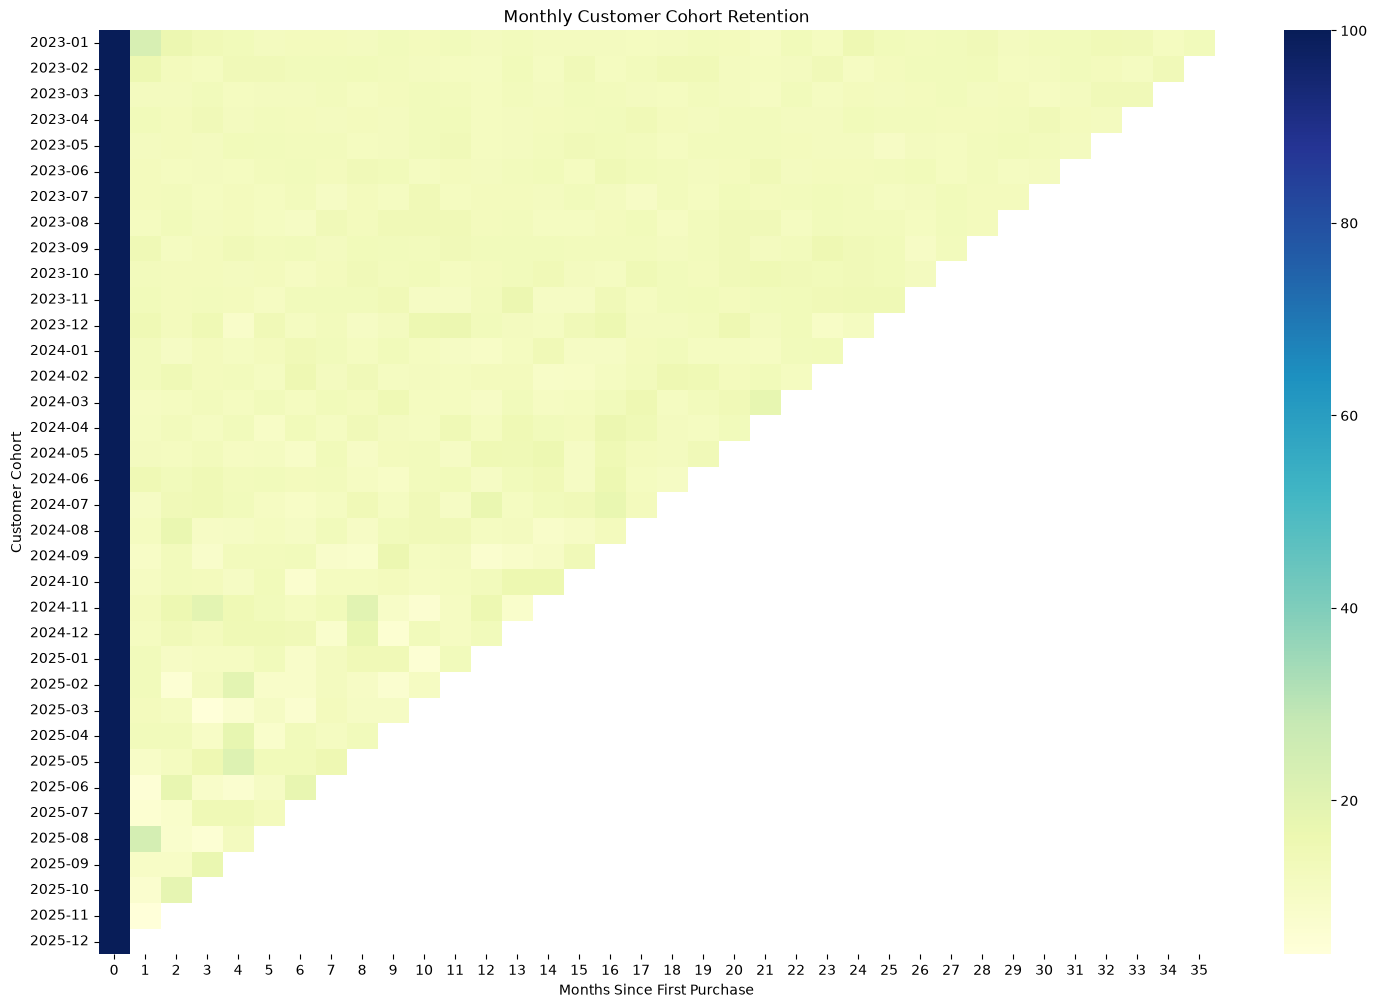

In [175]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 12))

sns.heatmap(
    retention_matrix,
    cmap="YlGnBu",
    annot=False,
    fmt=".1f"
)

plt.title("Monthly Customer Cohort Retention")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")

plt.show()

In [176]:
rfm["customer_lifetime_value"] = rfm["monetary"]

In [177]:
rfm[[
    "customer_id",
    "frequency",
    "monetary",
    "customer_lifetime_value"
]].head(10)

,customer_id,frequency,monetary,customer_lifetime_value
0,C000001,3,2003.88,2003.88
1,C000002,9,2728.14,2728.14
2,C000003,6,3614.70,3614.70
3,C000004,7,6410.11,6410.11
4,C000005,8,3245.15,3245.15
5,C000006,3,2029.93,2029.93
6,C000007,7,6453.48,6453.48
7,C000008,8,8081.93,8081.93
8,C000009,4,2333.75,2333.75
9,C000010,8,3967.10,3967.10


In [178]:
clv_analysis = rfm.groupby("customer_segment").agg(
    total_customers=("customer_id", "count"),
    average_clv=("customer_lifetime_value", "mean"),
    median_clv=("customer_lifetime_value", "median"),
    total_clv=("customer_lifetime_value", "sum")
).round(2)

In [179]:
clv_analysis.sort_values(
    by="average_clv",
    ascending=False
)

,total_customers,average_clv,median_clv,total_clv
customer_segment,,,,
Champions,4958,4733.19,4425.08,23467176.70
At Risk,1237,3806.56,3682.10,4708713.88
Loyal Customers,3730,3385.19,2886.36,12626771.40
Potential Loyalists,3057,2239.94,2133.46,6847504.80
Hibernating,6217,1836.95,1717.33,11420318.07
New Customers,651,1536.37,1406.41,1000175.17


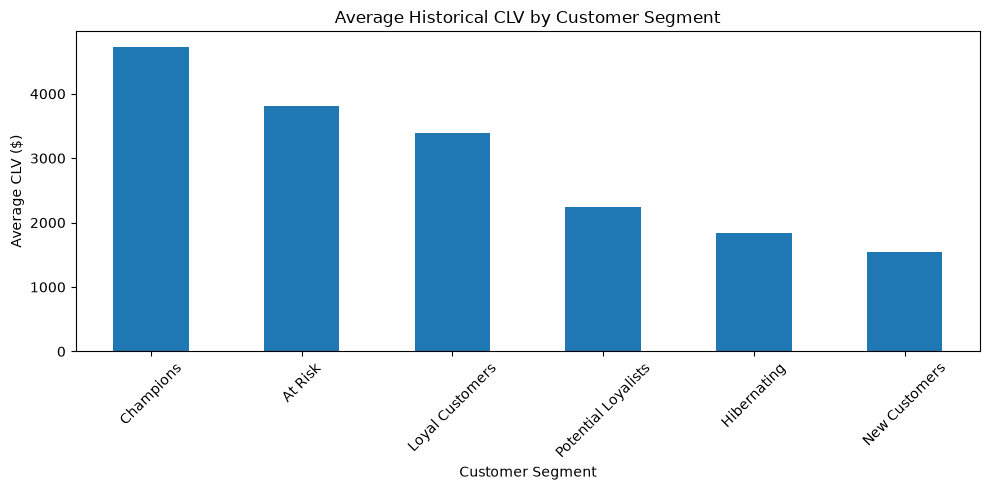

In [180]:
clv_analysis = clv_analysis.sort_values(
    by="average_clv",
    ascending=False
)

clv_analysis["average_clv"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Historical CLV by Customer Segment"
)

plt.ylabel("Average CLV ($)")
plt.xlabel("Customer Segment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [181]:
customer_purchase = rfm_orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    total_spent=("net_collected_amount", "sum"),
    average_order_value=("net_collected_amount", "mean")
).reset_index()

In [182]:
customer_purchase.describe().round(2)

,total_orders,total_spent,average_order_value
count,19850.00,19850.00,19850.00
mean,4.89,3026.23,618.74
std,2.22,1749.00,254.34
min,1.00,0.00,0.00
25%,3.00,1732.35,446.57
50%,5.00,2789.89,594.24
75%,6.00,4043.06,757.44
max,16.00,13836.62,2633.45


In [183]:
segment_purchase = customer_purchase.merge(
    rfm[["customer_id", "customer_segment"]],
    on="customer_id",
    how="left"
)

In [184]:
segment_purchase_analysis = segment_purchase.groupby(
    "customer_segment"
).agg(
    customers=("customer_id", "count"),
    average_orders=("total_orders", "mean"),
    average_spending=("total_spent", "mean"),
    average_order_value=("average_order_value", "mean")
).round(2)

In [185]:
segment_purchase_analysis.sort_values(
    by="average_spending",
    ascending=False
)

,customers,average_orders,average_spending,average_order_value
customer_segment,,,,
Champions,4958,7.12,4733.19,674.12
At Risk,1237,6.12,3806.56,622.40
Loyal Customers,3730,6.19,3385.19,543.00
Potential Loyalists,3057,3.62,2239.94,617.13
Hibernating,6217,2.96,1836.95,619.52
New Customers,651,2.46,1536.37,624.19


In [186]:
profit_analysis = valid_product_sales.copy()

In [187]:
profit_analysis["total_cost"] = (
    profit_analysis["unit_cost"]
    * profit_analysis["quantity"]
)

In [188]:
profit_analysis["gross_profit"] = (
    profit_analysis["line_total"]
    - profit_analysis["total_cost"]
)

In [189]:
profit_analysis[
    ["product_name", "quantity", "line_total",
     "total_cost", "gross_profit"]
].head(10)

,product_name,quantity,line_total,total_cost,gross_profit
0,Apparel Item 0871,1,19.05,12.81,6.24
4,Home Item 0717,2,200.23,112.18,88.05
5,Electronics Item 0458,1,272.25,179.17,93.08
6,Home Item 0765,1,6.77,4.85,1.92
7,Apparel Item 0847,1,41.99,28.22,13.77
8,Home Item 0591,1,280.79,146.23,134.56
9,Electronics Item 0074,1,267.90,125.66,142.24
10,Beauty Item 0833,1,211.54,90.65,120.89
11,Electronics Item 0470,1,120.72,44.25,76.47
12,Outdoors Item 0124,1,91.20,57.02,34.18


In [190]:
category_profit = profit_analysis.groupby("category").agg(
    total_units=("quantity", "sum"),
    total_revenue=("line_total", "sum"),
    total_cost=("total_cost", "sum"),
    gross_profit=("gross_profit", "sum")
).round(2)

In [191]:
category_profit["gross_margin_pct"] = (
    category_profit["gross_profit"]
    / category_profit["total_revenue"]
) * 100

In [192]:
category_profit.sort_values(
    by="gross_profit",
    ascending=False
).round(2)

,total_units,total_revenue,total_cost,gross_profit,gross_margin_pct
category,,,,,
electronics,53325,9903329.52,4821393.55,5081935.97,51.32
apparel,52879,10070386.43,5037979.19,5032407.24,49.97
outdoors,53791,9930336.66,4955618.74,4974717.92,50.10
office,52841,9668292.90,4718924.32,4949368.58,51.19
beauty,52651,9871192.14,4979290.97,4891901.17,49.56
home,53044,9276323.49,4610153.66,4666169.83,50.30


In [193]:
profit_analysis = profit_analysis.merge(
    orders[["order_id", "ordered_at"]],
    on="order_id",
    how="left"
)

In [194]:
profit_analysis["order_month"] = (
    profit_analysis["ordered_at"].dt.to_period("M")
)

C:\Users\AYUSH KUMAR\AppData\Local\Temp\ipykernel_8532\1142199499.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  profit_analysis["ordered_at"].dt.to_period("M")


In [195]:
profit_analysis[
    ["order_id", "ordered_at", "order_month",
     "line_total", "gross_profit"]
].head()

,order_id,ordered_at,order_month,line_total,gross_profit
0,O0000001,2025-05-09 16:24:59+00:00,2025-05,19.05,6.24
1,O0000003,2024-11-20 20:22:01+00:00,2024-11,200.23,88.05
2,O0000003,2024-11-20 20:22:01+00:00,2024-11,272.25,93.08
3,O0000004,2024-09-17 14:05:46+00:00,2024-09,6.77,1.92
4,O0000004,2024-09-17 14:05:46+00:00,2024-09,41.99,13.77


In [196]:
monthly_performance = profit_analysis.groupby("order_month").agg(
    total_revenue=("line_total", "sum"),
    total_cost=("total_cost", "sum"),
    gross_profit=("gross_profit", "sum"),
    total_units=("quantity", "sum")
).round(2)

In [197]:
monthly_performance["gross_margin_pct"] = (
    monthly_performance["gross_profit"]
    / monthly_performance["total_revenue"]
) * 100

In [198]:
monthly_performance.round(2)

,total_revenue,total_cost,gross_profit,total_units,gross_margin_pct
order_month,,,,,
2023-01,1592484.34,787288.99,805195.35,8542,50.56
2023-02,1505113.12,745749.11,759364.01,8279,50.45
2023-03,1765521.63,871321.81,894199.82,9424,50.65
2023-04,1638998.72,809677.47,829321.25,8930,50.60
2023-05,1625576.71,804212.67,821364.04,8883,50.53
2023-06,1548745.12,771067.59,777677.53,8393,50.21
2023-07,1655849.66,824287.03,831562.63,9108,50.22
2023-08,1571920.36,780610.11,791310.25,8595,50.34
2023-09,1608286.84,798683.49,809603.35,8772,50.34


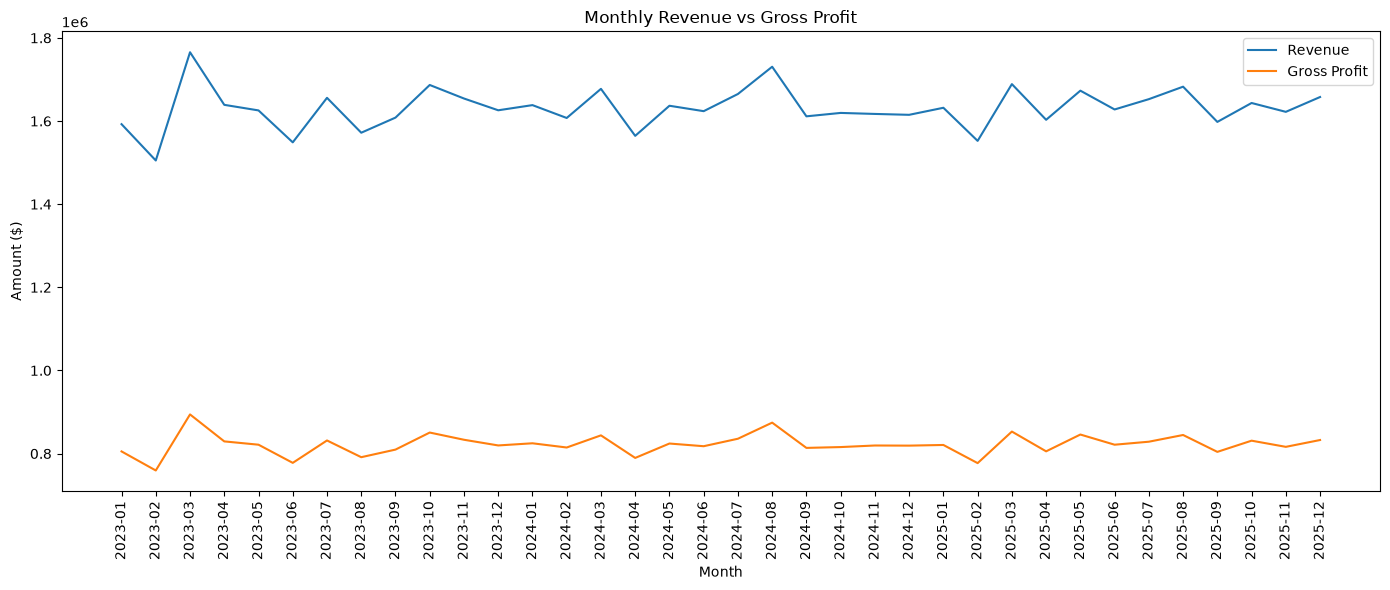

In [199]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance.index.astype(str),
    monthly_performance["total_revenue"],
    label="Revenue"
)

plt.plot(
    monthly_performance.index.astype(str),
    monthly_performance["gross_profit"],
    label="Gross Profit"
)

plt.title("Monthly Revenue vs Gross Profit")
plt.xlabel("Month")
plt.ylabel("Amount ($)")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()